# AfroViewz 01: Data acquisition

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JBWandera/Capstone/blob/afroviewz/notebooks/01_data_acquisition.ipynb)

**Workflow stage:** data acquisition (CRISP-DM: data understanding).

**Goal:** collect every image source, convert each one to a single format (COCO, one class: `pothole`), and keep a cleaned, downscaled copy on Google Drive. Nothing is split or merged here; that happens in notebook 02.

| Source | Region | Role | License |
|---|---|---|---|
| Stellenbosch Road Pothole Images | South Africa | train (incl. pothole free frames as hard negatives) | CC0 1.0 |
| Roboflow `pothole-detection-6vpbs` | Mixed | train (polygon masks for severity) | CC BY 4.0 (confirm) |
| Roboflow `potholes-detection-jbnou` (the v1 capstone data) | Mixed | train, and comparison with v1 | CC BY 4.0 (confirm) |
| Mapillary street photos, Uganda | Kampala, Entebbe, Masaka, Mbale, Lira | **holdout**: never trained on | CC BY-SA 4.0 |
| Own phone clips (optional) | Uganda | holdout | own |

The source list lives in `configs/sources.yaml`, so this notebook holds no hard coded paths or keys.

**Runtime:** CPU is enough. The Stellenbosch archive is about 25 GB; it is streamed and each image is shrunk as it arrives, so only about 2 GB touches the disk.

## 1. Setup

In [1]:
# Works on Colab and locally. On Colab: mounts Drive, gets the code, installs it.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/Capstone"):
        subprocess.run(["git", "clone", "-q", "-b", "afroviewz", "https://github.com/JBWandera/Capstone.git", "/content/Capstone"], check=True)
    else:
        subprocess.run(["git", "-C", "/content/Capstone", "pull", "-q"], check=True)
    os.chdir("/content/Capstone")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[data]"], check=True)
    sys.path.insert(0, "/content/Capstone/src")
from afroviewz import paths
print("data root:", paths.data_root())


data root: /home/claude/afz/data


## 2. Secrets

Add these in the Colab key icon (Secrets) panel, and switch on notebook access:

* `ROBOFLOW_API_KEY`: Roboflow, Settings, API Keys. **Use a new key**: the old one was published in the v1 notebook and must be revoked.
* `MAPILLARY_TOKEN`: create a free app at https://www.mapillary.com/dashboard/developers and copy the *client access token*.

Keys are read here and never printed or saved to the notebook.

In [2]:
def secret(name):
    """Colab Secrets on Colab, environment variables elsewhere. Never printed."""
    if IN_COLAB:
        from google.colab import userdata
        try:
            return userdata.get(name)
        except Exception:
            return None
    return os.environ.get(name)

ROBOFLOW_API_KEY = secret("ROBOFLOW_API_KEY")
MAPILLARY_TOKEN = secret("MAPILLARY_TOKEN")
print("Roboflow key set:", bool(ROBOFLOW_API_KEY), "| Mapillary token set:", bool(MAPILLARY_TOKEN))


Roboflow key set: True | Mapillary token set: True


## 3. The source register

In [3]:
import json
import pandas as pd
from afroviewz.data import sources, build, coco as C

cfg = sources.load_config()
print("raw downloads ->", paths.raw_root())
print("cleaned copies ->", paths.data_root() / "interim")
pd.DataFrame(cfg).T[["title", "region", "role", "license", "download"]]


raw downloads -> /home/claude/afz/raw
cleaned copies -> /home/claude/afz/data/interim


,title,region,role,license,download
stellenbosch,"Road Pothole Images (Stellenbosch University, ...",South Africa,train,CC0-1.0,dataset-tools
roboflow_seg,"pothole detection (Roboflow Universe, project-...",Mixed,train,CC-BY-4.0,roboflow
capstone_v1,"Potholes detection (Roboflow Universe, muhamma...",Mixed,train,CC-BY-4.0,roboflow
uganda_mapillary,"Mapillary street level images, Uganda",Uganda,holdout,CC-BY-SA-4.0,mapillary
uganda_phone,"AfroViewz phone footage, Uganda (optional)",Uganda,holdout,Own,manual


## 4. Download

Each source is downloaded only if its raw folder is empty, so the cell can be re-run after a disconnect.

In [4]:
def fetch(name):
    d = paths.raw_dir(name)
    done = (d / ".complete").exists() or (d / "metadata.csv").exists() or (d / "train").exists()
    if done:
        print(f"{name}: already downloaded at {d}")
        return d
    return sources.download(name, cfg, roboflow_key=ROBOFLOW_API_KEY, mapillary_token=MAPILLARY_TOKEN)

for name in ["capstone_v1", "roboflow_seg"]:
    fetch(name)


capstone_v1: already downloaded at /home/claude/afz/raw/capstone_v1
roboflow_seg: already downloaded at /home/claude/afz/raw/roboflow_seg


In [5]:
# About 25 GB streamed and shrunk on the fly to about 2 GB. Allow 30 to 45 minutes.
fetch("stellenbosch")


stellenbosch: already downloaded at /home/claude/afz/raw/stellenbosch


PosixPath('/home/claude/afz/raw/stellenbosch')

The Ugandan photos are chosen once by a search (every photo since 2019 inside each town's box, then thinned to frames at least 30 m apart along each drive and capped at 2,000 for Kampala and 300 for each other town, spread over as many drives as possible). The chosen photo ids are committed in `configs/manifests/uganda_mapillary.csv`, so every later run downloads exactly the same 3,200 photos.

In [6]:
fetch("uganda_mapillary")


uganda_mapillary: already downloaded at /home/claude/afz/raw/uganda_mapillary


PosixPath('/home/claude/afz/raw/uganda_mapillary')

## 5. Convert, clean and store each source

For every source: map the pothole categories to one class and drop the rest, clip boxes to the image, drop boxes under 4 px and exact duplicate boxes, then save a JPEG copy with the long side at 1280 px (1600 px for the dashcam sources, where potholes are small) and the boxes scaled to match. Each source gets a `report.json` with before and after counts.

Two quirks found while inspecting the Roboflow downloads are handled through `configs/sources.yaml`:
* both uploads name the pothole class `"0"`, so a name rule alone would throw every label away;
* `roboflow_seg` holds 3 augmented copies of each training photo (flips, 90 degree turns, crops). Only one copy per photo is kept, because training applies its own augmentation and sideways roads are not something a dashcam sees.

In [7]:
reports = {}
for name in ["capstone_v1", "roboflow_seg", "stellenbosch", "uganda_mapillary"]:
    out = paths.interim_dir(name)
    if (out / "coco.json").exists():
        print(f"{name}: already prepared")
        reports[name] = json.loads((out / "report.json").read_text())
        continue
    coco, root = sources.to_coco(name, cfg)
    reports[name] = build.prepare_source(name, coco, root, out, **sources.prepare_kwargs(name, cfg))

rows = []
for name, r in reports.items():
    rows.append({
        "source": name,
        "images_in": r["before"]["images"],
        "boxes_in": r["before"]["annotations"],
        "images_out": r["after"]["images"],
        "boxes_out": r["after"]["annotations"],
        "with_potholes": r["after"]["images_with_potholes"],
        "pothole_free": r["after"]["negative_images"],
        "boxes_clipped": r["boxes"]["clipped"],
        "tiny_dropped": r["boxes"]["dropped_tiny"],
        "dup_boxes_dropped": r["boxes"]["dropped_duplicate"],
        "other_classes_dropped": sum(r["categories"]["dropped_by_category"].values()),
        "augmented_copies_dropped": r.get("augmented_copies_dropped", 0),
        "unreadable_images": r["image_problem_count"],
    })
acq = pd.DataFrame(rows).set_index("source")
acq.to_csv(paths.data_root() / "interim" / "acquisition_summary.csv")
acq


capstone_v1: already prepared
roboflow_seg: already prepared
stellenbosch: already prepared
uganda_mapillary: already prepared


,images_in,boxes_in,images_out,boxes_out,with_potholes,pothole_free,boxes_clipped,tiny_dropped,dup_boxes_dropped,other_classes_dropped,augmented_copies_dropped,unreadable_images
source,,,,,,,,,,,,
capstone_v1,665,1739,665,1738,665,0,0,1,0,0,0,0
roboflow_seg,2964,6116,1342,2915,1340,2,0,3,0,0,1622,0
stellenbosch,5445,7588,5445,7109,2920,2525,0,119,360,0,0,0
uganda_mapillary,3200,0,3200,0,0,3200,0,0,0,0,0,0


## 6. A first look

A few random images per source with their boxes, to confirm the conversion is right before any modelling. The Uganda Mapillary photos have no boxes yet: they are labelled in notebook 04.

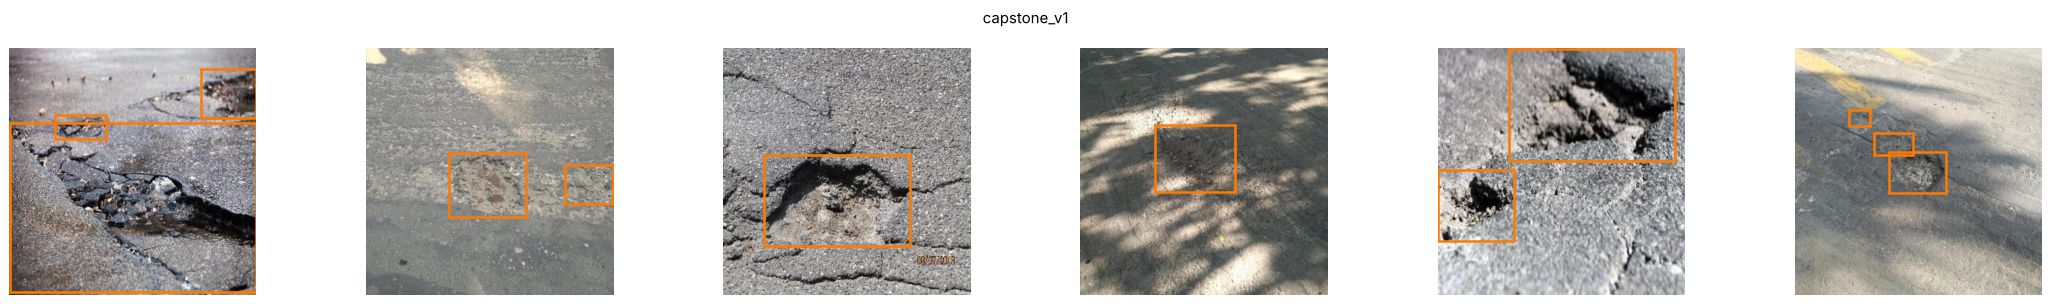

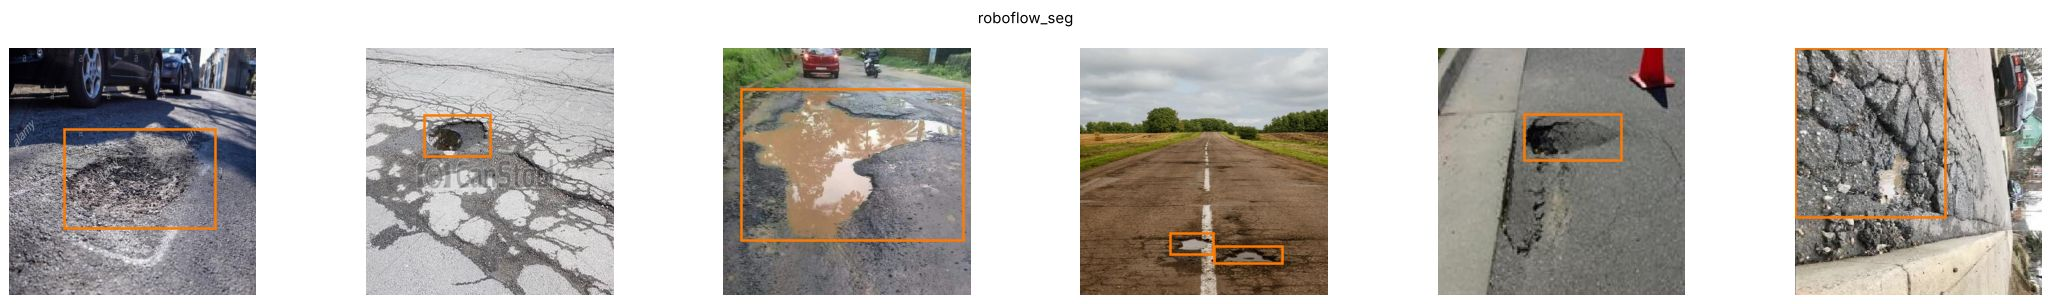

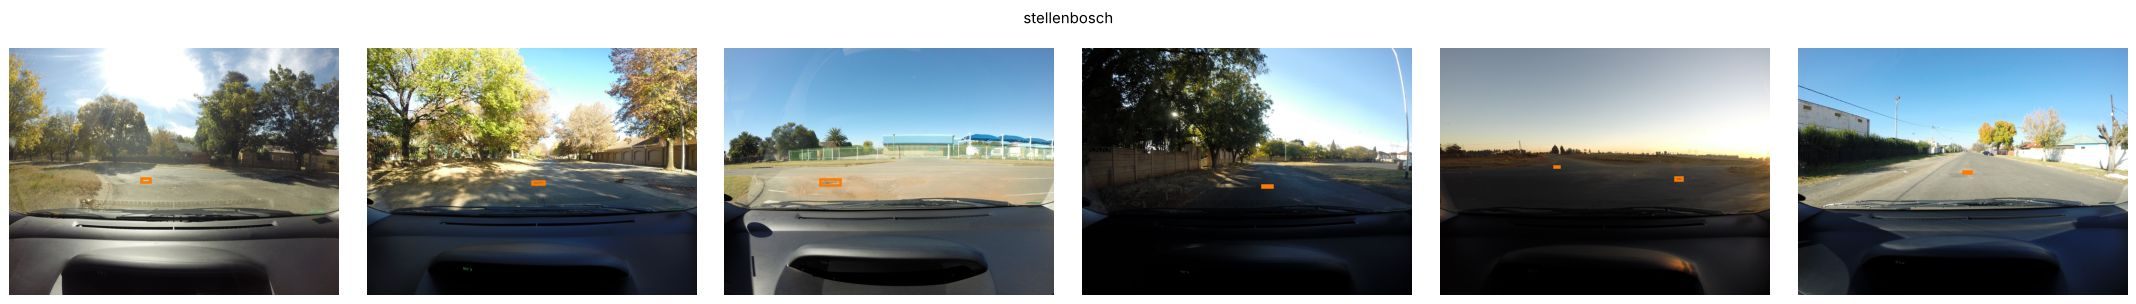

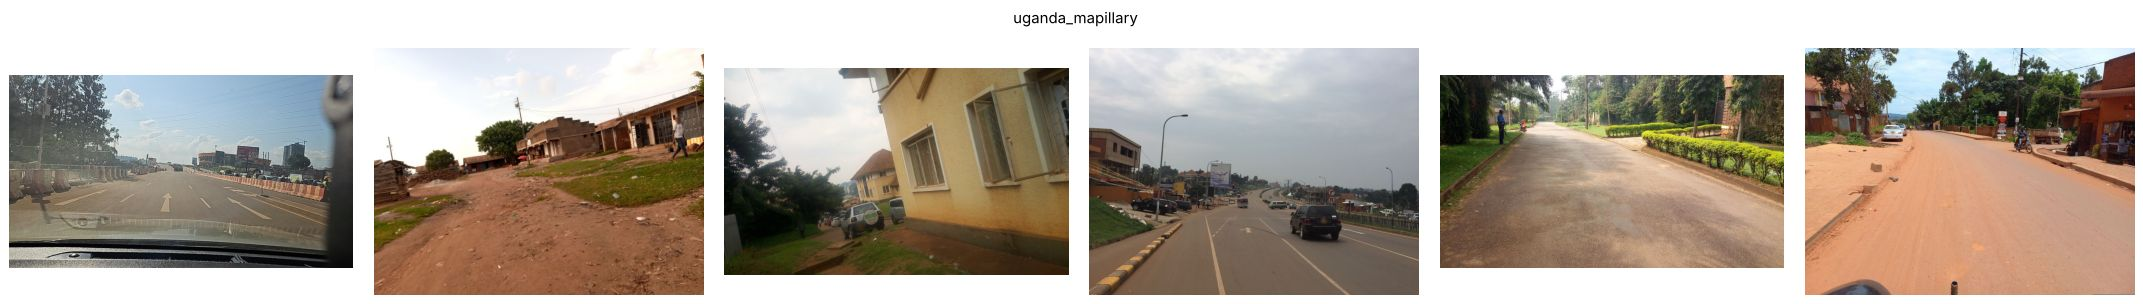

In [8]:
import random
import matplotlib.pyplot as plt
from afroviewz.viz import show_jpeg
import matplotlib.patches as patches
from PIL import Image

def show_samples(name, n=6, seed=0):
    d = paths.interim_dir(name)
    coco = C.load(d / "coco.json")
    by_img = {}
    for a in coco["annotations"]:
        by_img.setdefault(a["image_id"], []).append(a["bbox"])
    pool = [im for im in coco["images"] if im["id"] in by_img] or coco["images"]
    picks = random.Random(seed).sample(pool, min(n, len(pool)))
    fig, axes = plt.subplots(1, len(picks), figsize=(4 * len(picks), 3.4))
    for ax, im in zip(axes, picks):
        ax.imshow(Image.open(d / "images" / im["file_name"]))
        for x, y, w, h in by_img.get(im["id"], []):
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=2, ec="#ff7a00"))
        ax.set_axis_off()
    fig.suptitle(name)
    plt.tight_layout()
    show_jpeg(fig)

for name in reports:
    show_samples(name)


## 7. Uganda coverage map

Where the Ugandan holdout photos were taken. This is also the first view of what the app map will show.

area
entebbe     300
kampala    2000
lira        300
masaka      300
mbale       300
Name: images, dtype: int64


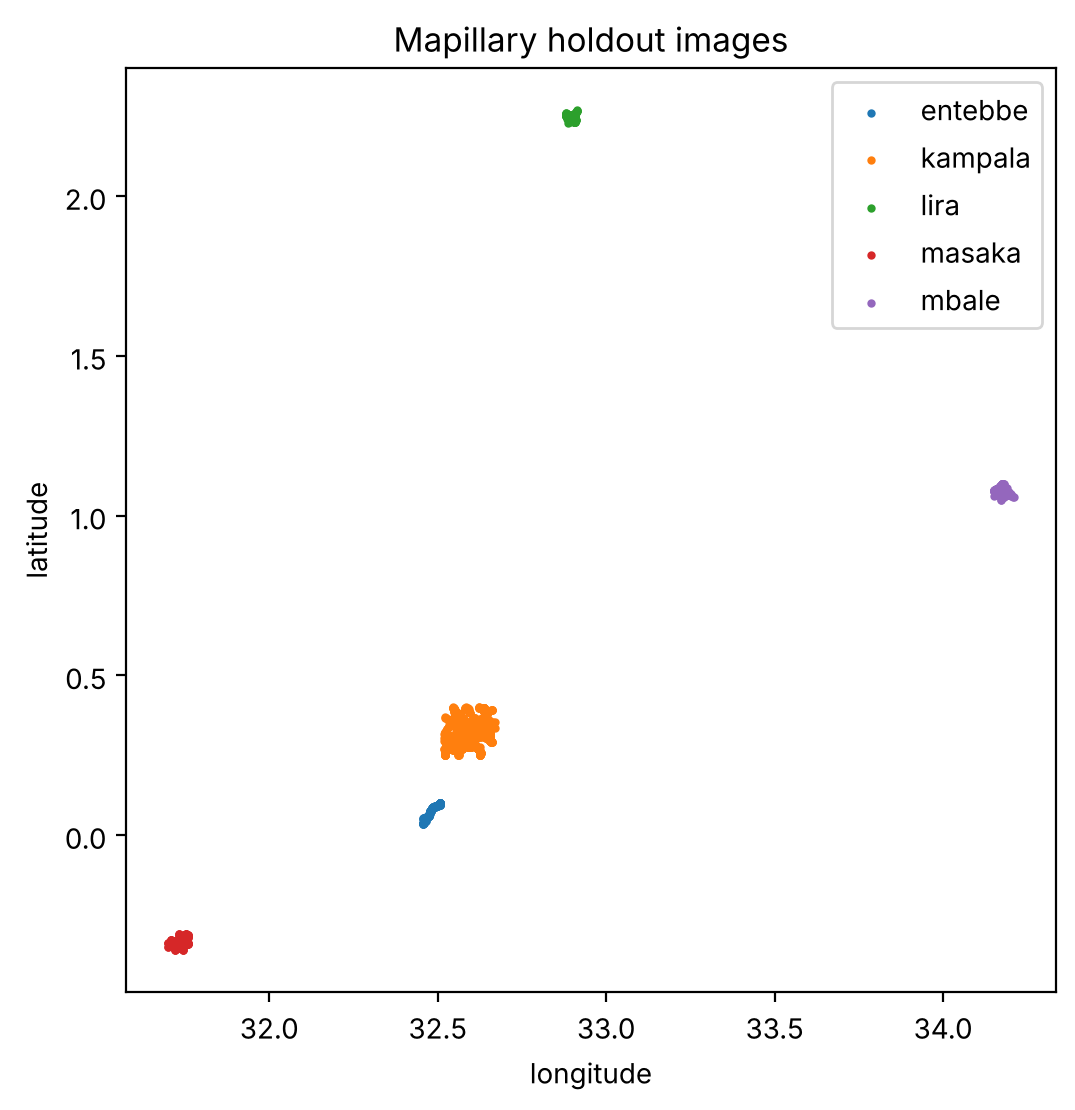

In [9]:
meta = pd.read_csv(paths.raw_dir("uganda_mapillary") / "metadata.csv")
print(meta.groupby("area").size().rename("images"))
fig, ax = plt.subplots(figsize=(6, 6))
for area, g in meta.groupby("area"):
    ax.scatter(g.lon, g.lat, s=4, label=area)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.legend(); ax.set_title("Mapillary holdout images")
plt.show()
meta.to_csv(paths.interim_dir("uganda_mapillary") / "metadata.csv", index=False)


## Outputs

On Drive under `AfroViewz/data/interim/<source>/`: `images/`, `coco.json`, `report.json`, plus `acquisition_summary.csv`.

**Next:** notebook 02 merges the sources, finds near duplicates and makes a leak free train, valid, test split.